# Autoencoders: exemplos

Exemplos em PyTorch usando o conjunto *digits* (imagens 8×8 de dígitos manuscritos, já vem no scikit-learn).

Os resultados que comparam métodos são a média ± desvio padrão de `N_RODADAS` treinamentos com sementes diferentes.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.linalg import subspace_angles
from sklearn.decomposition import PCA

import libs
from libs import CORES, media_dp

torch.set_num_threads(2)
N_RODADAS = 5

X_tr, X_te, y_tr, y_te = libs.carregar_digits()
print("treino:", tuple(X_tr.shape), " teste:", tuple(X_te.shape))

def mse_pca(k, Xtr=X_tr, Xte=X_te):
    p = PCA(n_components=k).fit(Xtr.numpy())
    return np.mean((p.inverse_transform(p.transform(Xte.numpy())) - Xte.numpy()) ** 2)

treino: (1347, 64)  teste: (450, 64)


## 1. Autoencoder nos dígitos

Cada imagem vira um vetor de 64 valores e o código $h$ tem só 8 dimensões. A rede é $64 \to 32 \to 8 \to 32 \to 64$ com ReLU, treinada para reconstruir a própria entrada (MSE).

MSE no teste: 0.0151 ± 0.0006


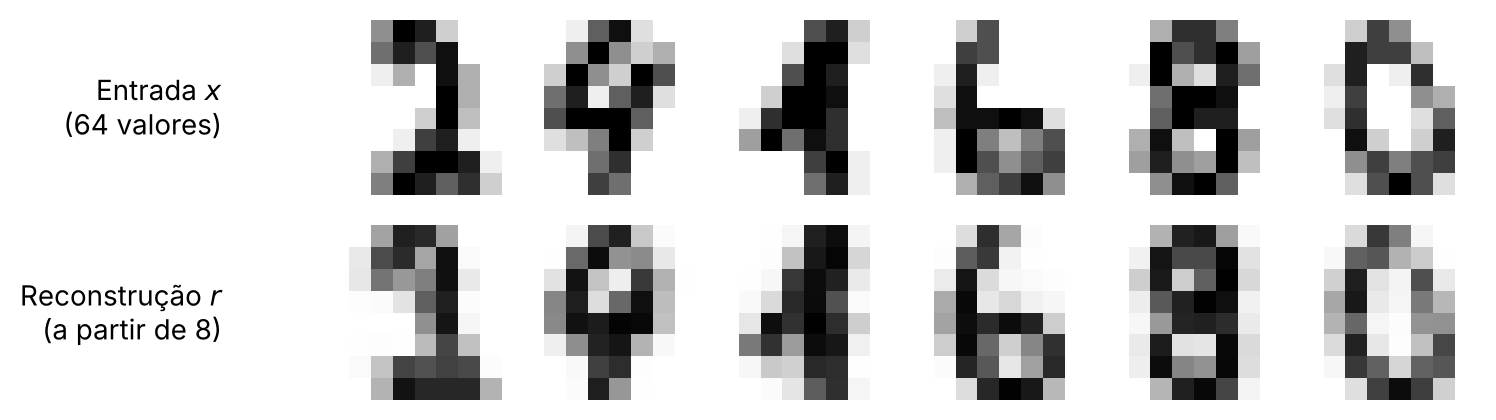

In [2]:
modelos, erros = libs.varias_rodadas(
    lambda: libs.Autoencoder(n_codigo=8, ocultas=[32], ativacao="relu"),
    X_tr, N_RODADAS, avaliar=lambda m: libs.erro_reconstrucao(m, X_te), epocas=400, lr=3e-3)
m, d = media_dp(erros)
print(f"MSE no teste: {m:.4f} ± {d:.4f}")

idx = [0, 4, 5, 8, 15, 20]
fig = libs.mostrar_imagens([X_te[idx], libs.reconstruir(modelos[0], X_te[idx])],
                           ["Entrada $x$\n(64 valores)", "Reconstrução $r$\n(a partir de 8)"], n=6)
libs.salvar(fig, "ae_digitos_reconstrucao")
plt.show()

A reconstrução guarda o formato do dígito, mas perde detalhes: é isso que queremos, já que o código não tem espaço para tudo.

## 2. Relação com PCA

Com encoder e decoder **lineares** e perda MSE, o autoencoder aprende o mesmo subespaço do PCA. Para conferir, comparamos o erro e o ângulo entre os dois subespaços (código com 2 dimensões).

In [3]:
def avalia_linear(m):
    W = m.decodificador[0].weight.detach().numpy()          # colunas geram o subespaço do decoder
    p = PCA(n_components=2).fit(X_tr.numpy())
    return libs.erro_reconstrucao(m, X_te), np.degrees(subspace_angles(W, p.components_.T)).max()

_, res = libs.varias_rodadas(
    lambda: libs.Autoencoder(n_codigo=2, ativacao="linear", saida="linear"),
    X_tr, N_RODADAS, avaliar=avalia_linear, epocas=600, lr=1e-2)
(m_mse, m_ang), (d_mse, d_ang) = media_dp(res)
print(f"MSE PCA:              {mse_pca(2):.5f}")
print(f"MSE autoencoder linear: {m_mse:.5f} ± {d_mse:.5f}")
print(f"maior ângulo entre os subespaços: {m_ang:.2f} ± {d_ang:.2f} graus")

MSE PCA:              0.05302
MSE autoencoder linear: 0.05304 ± 0.00004
maior ângulo entre os subespaços: 1.10 ± 0.65 graus


Mesmo erro e ângulo perto de zero. Com **não linearidades** o autoencoder vira uma versão não linear do PCA e consegue seguir dados curvos. Um exemplo simples em 2D: pontos em volta de um arco, comprimidos para 1 dimensão (rede $2 \to 32 \to 1 \to 32 \to 2$ com tanh).

MSE PCA: 0.0160   MSE autoencoder: 0.0008 ± 0.0000


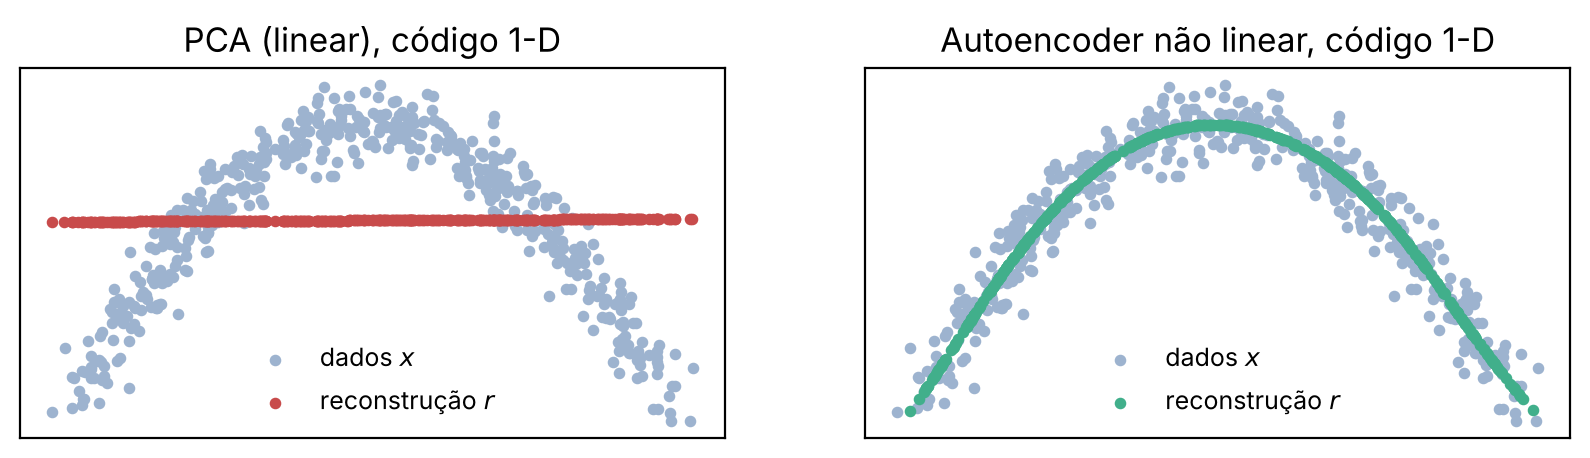

In [4]:
X_arco = libs.dados_arco()
p1 = PCA(n_components=1).fit(X_arco.numpy())
rec_pca = p1.inverse_transform(p1.transform(X_arco.numpy()))

modelos_arco, erros_arco = libs.varias_rodadas(
    lambda: libs.Autoencoder(n_entrada=2, n_codigo=1, ocultas=[32], ativacao="tanh", saida="linear"),
    X_arco, N_RODADAS, avaliar=lambda m: libs.erro_reconstrucao(m, X_arco),
    epocas=1000, lr=3e-3, tam_lote=64)
m, d = media_dp(erros_arco)
print(f"MSE PCA: {np.mean((rec_pca - X_arco.numpy()) ** 2):.4f}   MSE autoencoder: {m:.4f} ± {d:.4f}")

rec_ae = libs.reconstruir(modelos_arco[0], X_arco).numpy()
fig, ax = plt.subplots(1, 2, figsize=(10, 2.4))
for a, rec, cor, titulo in [(ax[0], rec_pca, CORES["pca"], "PCA (linear), código 1-D"),
                            (ax[1], rec_ae, CORES["verde"], "Autoencoder não linear, código 1-D")]:
    a.scatter(X_arco[:, 0], X_arco[:, 1], s=10, color=CORES["claro"], label="dados $x$")
    a.scatter(rec[:, 0], rec[:, 1], s=10, color=cor, label="reconstrução $r$")
    a.set_title(titulo); a.set_xticks([]); a.set_yticks([])
    a.legend(loc="lower center", frameon=False, fontsize=9)
libs.salvar(fig, "pca_vs_ae")
plt.show()

Voltando aos dígitos: como o erro muda com o tamanho do código? (autoencoder não linear $64 \to 128 \to k$, ReLU)

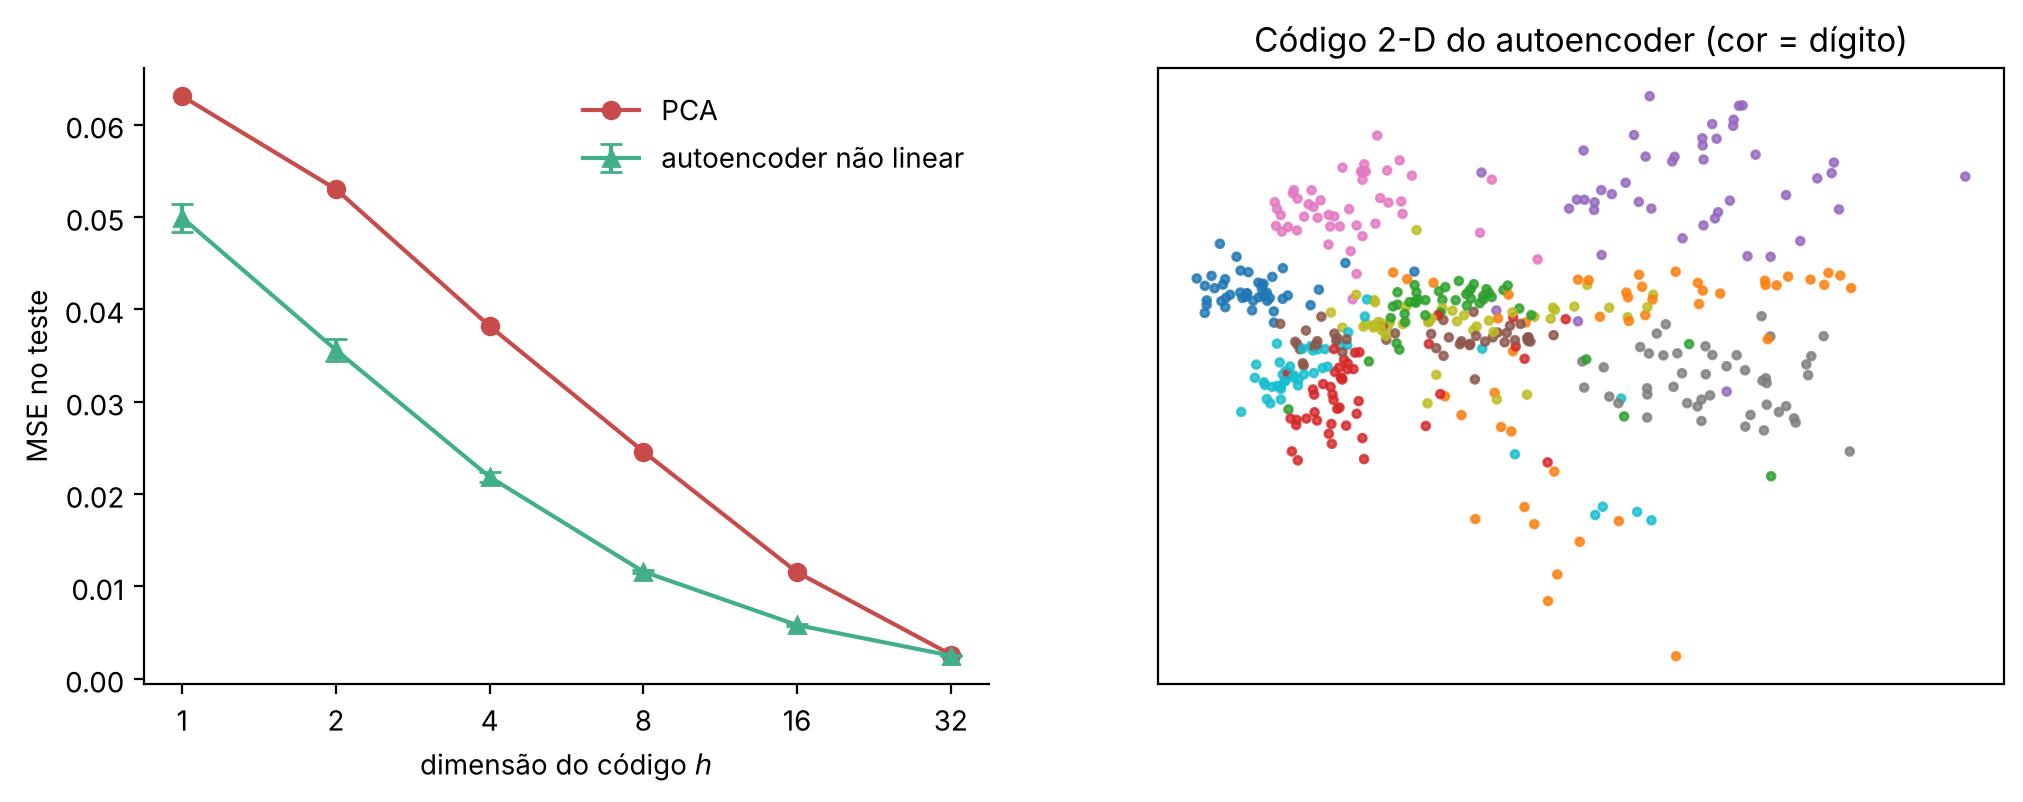

In [5]:
ks = [1, 2, 4, 8, 16, 32]
erro_pca = [mse_pca(k) for k in ks]
erro_ae, modelos_k = [], {}
for k in ks:
    mods, e = libs.varias_rodadas(lambda: libs.Autoencoder(n_codigo=k, ocultas=[128]),
                                  X_tr, N_RODADAS, avaliar=lambda m: libs.erro_reconstrucao(m, X_te),
                                  epocas=400, lr=3e-3)
    erro_ae.append(media_dp(e)); modelos_k[k] = mods[0]
m_ae, d_ae = np.array(erro_ae).T

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, erro_pca, "o-", color=CORES["pca"], label="PCA")
ax[0].errorbar(ks, m_ae, yerr=d_ae, fmt="^-", capsize=4, color=CORES["verde"], label="autoencoder não linear")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(ks); ax[0].set_xticklabels(ks)
ax[0].set_xlabel("dimensão do código $h$"); ax[0].set_ylabel("MSE no teste")
ax[0].legend(frameon=False); libs.limpar_eixos(ax[0])

libs.dispersao_codigo(ax[1], libs.codificar(modelos_k[2], X_te), y_te, "Código 2-D do autoencoder (cor = dígito)")
libs.salvar(fig, "erro_vs_codigo")
plt.show()

A vantagem do autoencoder é maior quando o gargalo é apertado. E mesmo sem ver os rótulos, ele separa bem os dígitos no código 2-D.

## 3. Capacidade demais e esparsidade

Se o código for maior que a entrada (*overcomplete*), nada impede a rede de aprender a copiar. Para testar, passamos **imagens de ruído** (que não são dígitos): um modelo que aprendeu os dígitos deveria reconstruí-las mal.

A versão esparsa usa o mesmo código grande, mas soma $\lambda \sum_i |h_i|$ à perda.

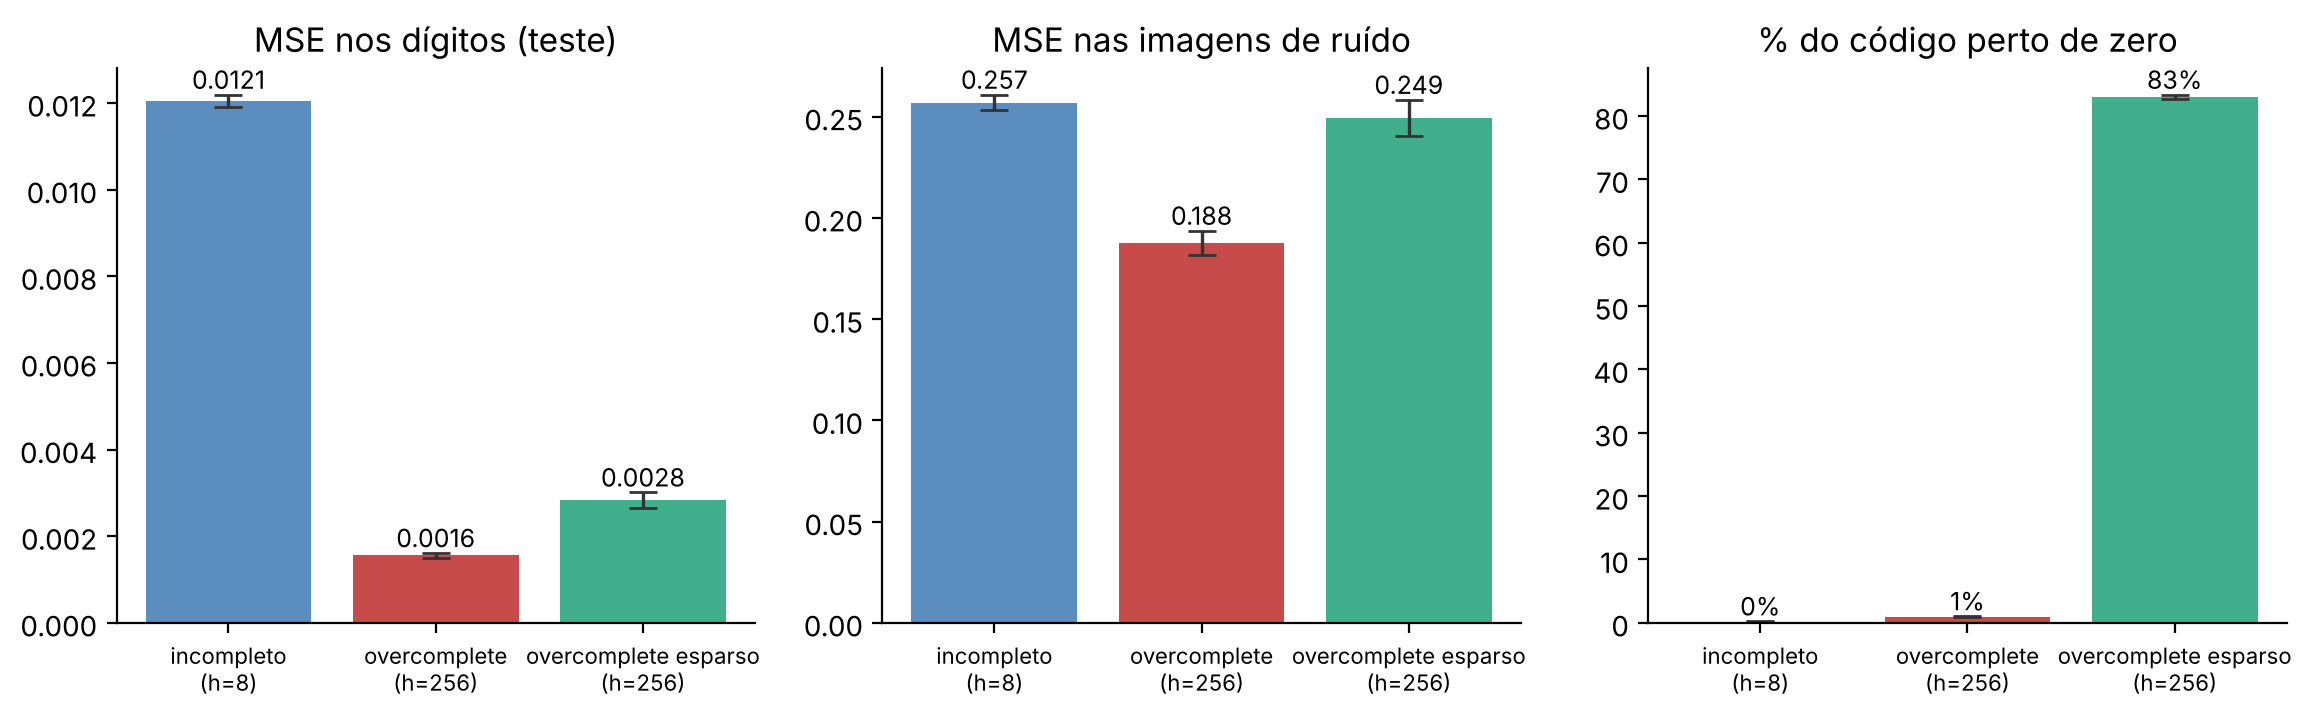

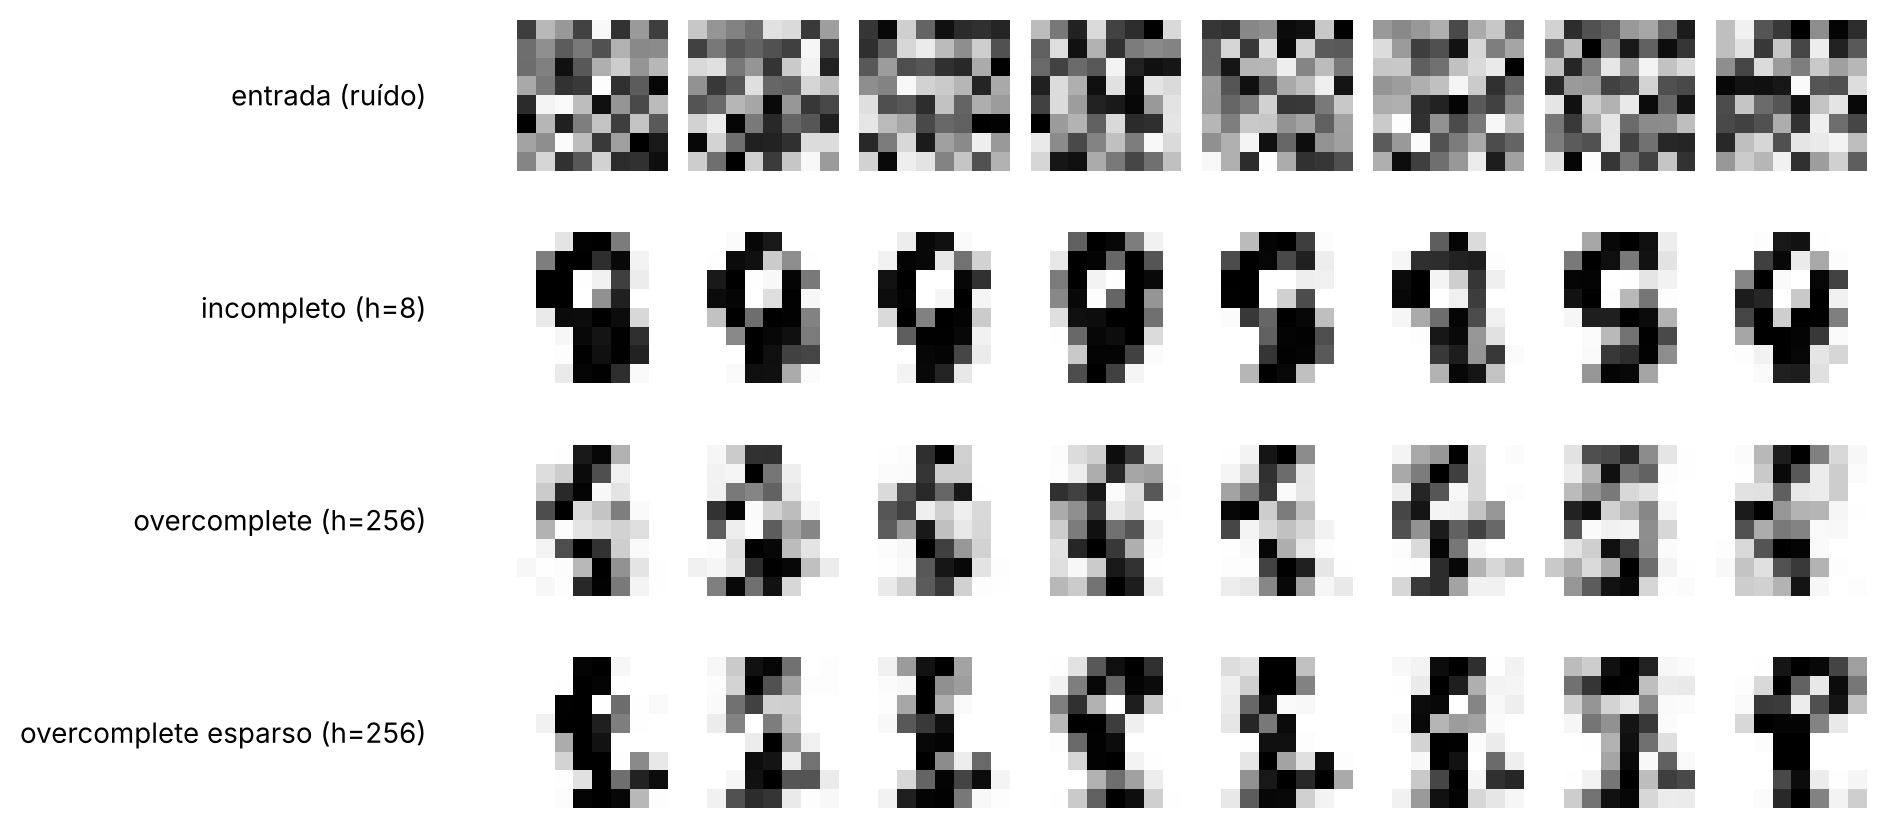

In [6]:
X_ruido = torch.rand(len(X_te), 64, generator=torch.Generator().manual_seed(1))

def avalia_reg(m):
    H = libs.codificar(m, X_te)
    return (libs.erro_reconstrucao(m, X_te), libs.erro_reconstrucao(m, X_ruido),
            100 * (H.abs() < 1e-2).float().mean().item())

configs = {"incompleto\n(h=8)": dict(k=8, l1=0.0),
           "overcomplete\n(h=256)": dict(k=256, l1=0.0),
           "overcomplete esparso\n(h=256)": dict(k=256, l1=1e-3)}
res_reg, mod_reg = {}, {}
for nome, c in configs.items():
    mods, r = libs.varias_rodadas(lambda: libs.Autoencoder(n_codigo=c["k"], ocultas=[128]),
                                  X_tr, N_RODADAS, avaliar=avalia_reg, epocas=400, lambda_l1=c["l1"])
    res_reg[nome], mod_reg[nome] = media_dp(r), mods[0]

nomes = list(res_reg)
cores = [CORES["azul"], CORES["pca"], CORES["verde"]]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, (titulo, fmt) in enumerate([("MSE nos dígitos (teste)", "{:.4f}"),
                                   ("MSE nas imagens de ruído", "{:.3f}"),
                                   ("% do código perto de zero", "{:.0f}%")]):
    libs.barras_com_erro(ax[i], nomes, [res_reg[n][0][i] for n in nomes],
                         [res_reg[n][1][i] for n in nomes], cores, fmt)
    ax[i].set_title(titulo); ax[i].tick_params(axis="x", labelsize=8)
libs.salvar(fig, "esparso_metricas")
plt.show()

fig = libs.mostrar_imagens([X_ruido[:8]] + [libs.reconstruir(m, X_ruido[:8]) for m in mod_reg.values()],
                           ["entrada (ruído)"] + [n.replace("\n", " ") for n in nomes], n=8)
libs.salvar(fig, "esparso_ruido")
plt.show()

O overcomplete sem regularização tem o menor erro nos dígitos, mas é o que mais deixa passar o ruído. O incompleto e o esparso "puxam" o ruído para algo parecido com um dígito. No esparso, a maior parte das unidades do código fica em zero.

## 4. Profundidade

Mesmo código de 8 dimensões, mudando só o número de camadas do encoder (o decoder é simétrico, tanh):
- raso: $64 \to 8$
- 2 camadas: $64 \to 32 \to 8$
- 3 camadas: $64 \to 64 \to 32 \to 8$

Raso 1 camada no encoder            0.0205 ± 0.0001


Profundo 2 camadas                  0.0135 ± 0.0005


Mais profundo 3 camadas             0.0126 ± 0.0005
PCA                                 0.0246


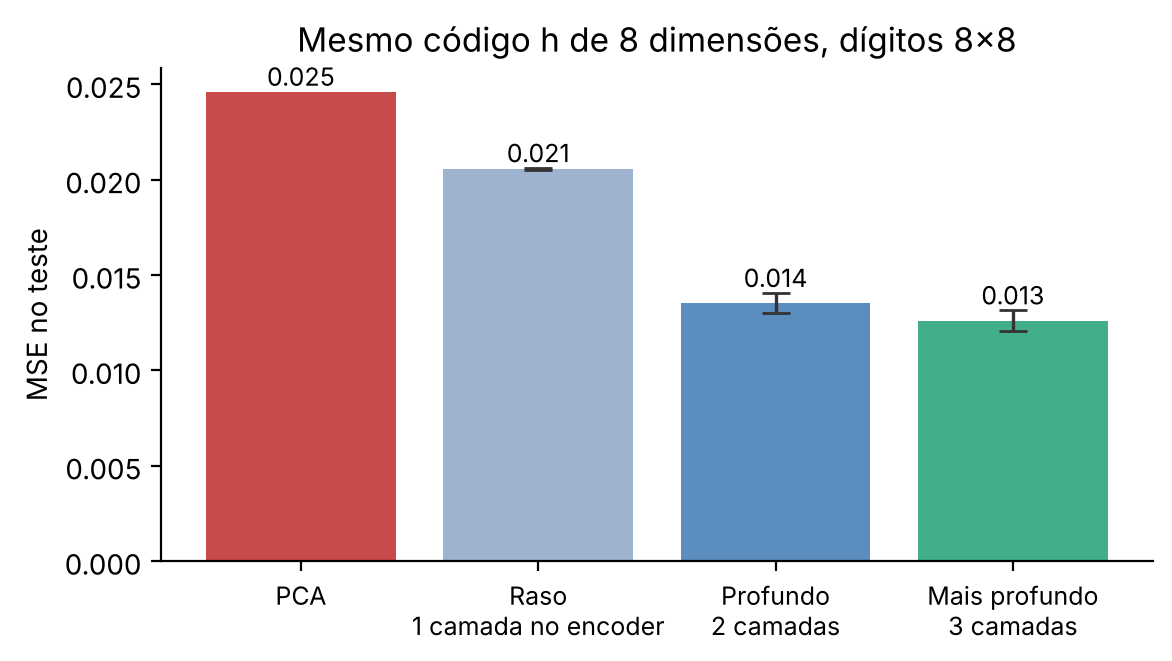

In [7]:
arquiteturas = {"Raso\n1 camada no encoder": [], "Profundo\n2 camadas": [32], "Mais profundo\n3 camadas": [64, 32]}
res_prof = {}
for nome, oc in arquiteturas.items():
    _, e = libs.varias_rodadas(lambda: libs.Autoencoder(n_codigo=8, ocultas=oc, ativacao="tanh"),
                               X_tr, N_RODADAS, avaliar=lambda m: libs.erro_reconstrucao(m, X_te),
                               epocas=600, lr=3e-3)
    res_prof[nome] = media_dp(e)
    print(f"{nome.replace(chr(10), ' '):35s} {res_prof[nome][0]:.4f} ± {res_prof[nome][1]:.4f}")
print(f"{'PCA':35s} {mse_pca(8):.4f}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
libs.barras_com_erro(ax, ["PCA"] + list(res_prof),
                     [mse_pca(8)] + [v[0] for v in res_prof.values()],
                     [0] + [v[1] for v in res_prof.values()],
                     [CORES["pca"], CORES["claro"], CORES["azul"], CORES["verde"]])
ax.set_ylabel("MSE no teste"); ax.tick_params(axis="x", labelsize=9)
ax.set_title("Mesmo código h de 8 dimensões, dígitos 8×8")
libs.salvar(fig, "raso_vs_profundo")
plt.show()

O raso fica perto do PCA e cada camada a mais diminui o erro. O PCA não tem barra de erro porque não depende de inicialização.

## 5. Denoising autoencoder

Em vez de copiar, a rede recebe a imagem com ruído $\tilde{x}$ e tem que devolver a imagem limpa $x$:

$$L\big(x,\, g(f(\tilde{x}))\big)$$

Comparamos com um autoencoder igual treinado sem ruído (ruído gaussiano, $\sigma = 0{,}3$).

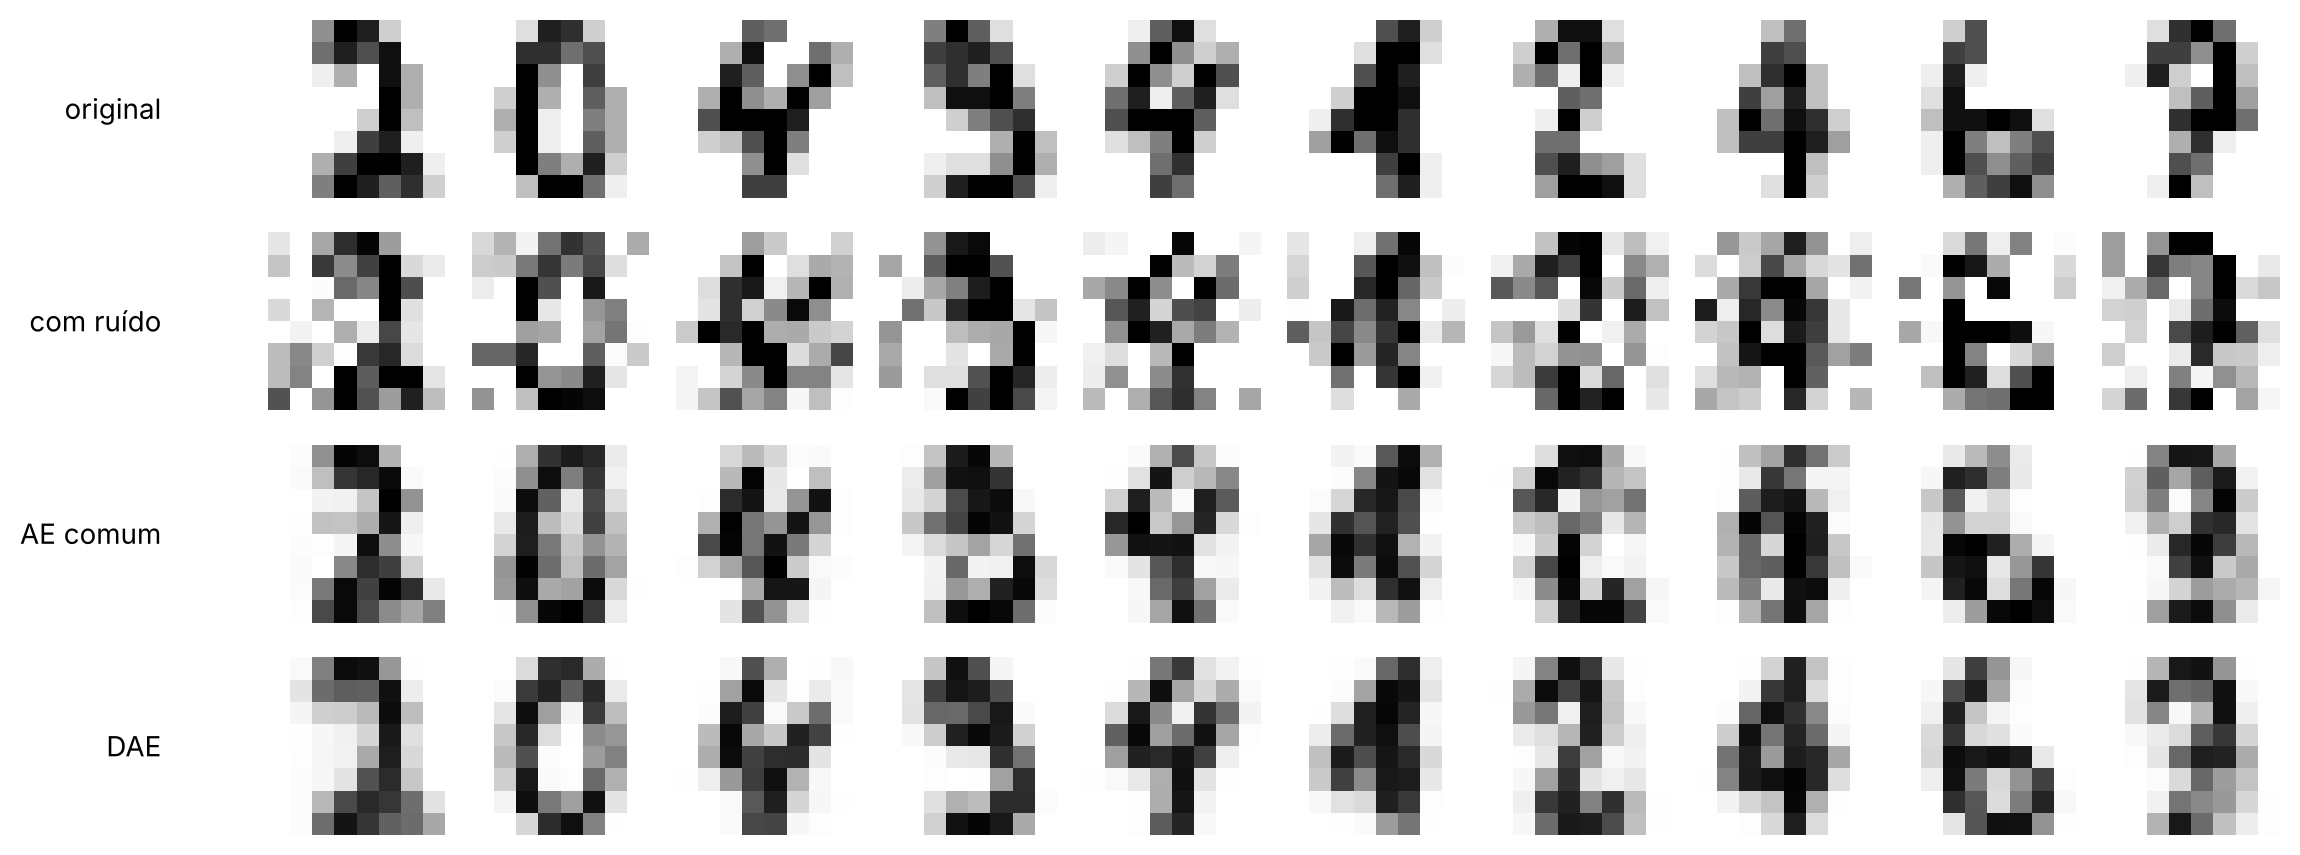

In [8]:
sigma = 0.3
criar = lambda: libs.Autoencoder(n_codigo=32, ocultas=[128])
aes, _ = libs.varias_rodadas(criar, X_tr, N_RODADAS, epocas=400)
daes, _ = libs.varias_rodadas(criar, X_tr, N_RODADAS, epocas=400, sigma_ruido=sigma)

torch.manual_seed(123)
X_te_ruido = libs.ruido_gaussiano(X_te, sigma)
fig = libs.mostrar_imagens([X_te[:10], X_te_ruido[:10], libs.reconstruir(aes[0], X_te_ruido[:10]),
                            libs.reconstruir(daes[0], X_te_ruido[:10])],
                           ["original", "com ruído", "AE comum", "DAE"])
libs.salvar(fig, "denoising_digitos")
plt.show()

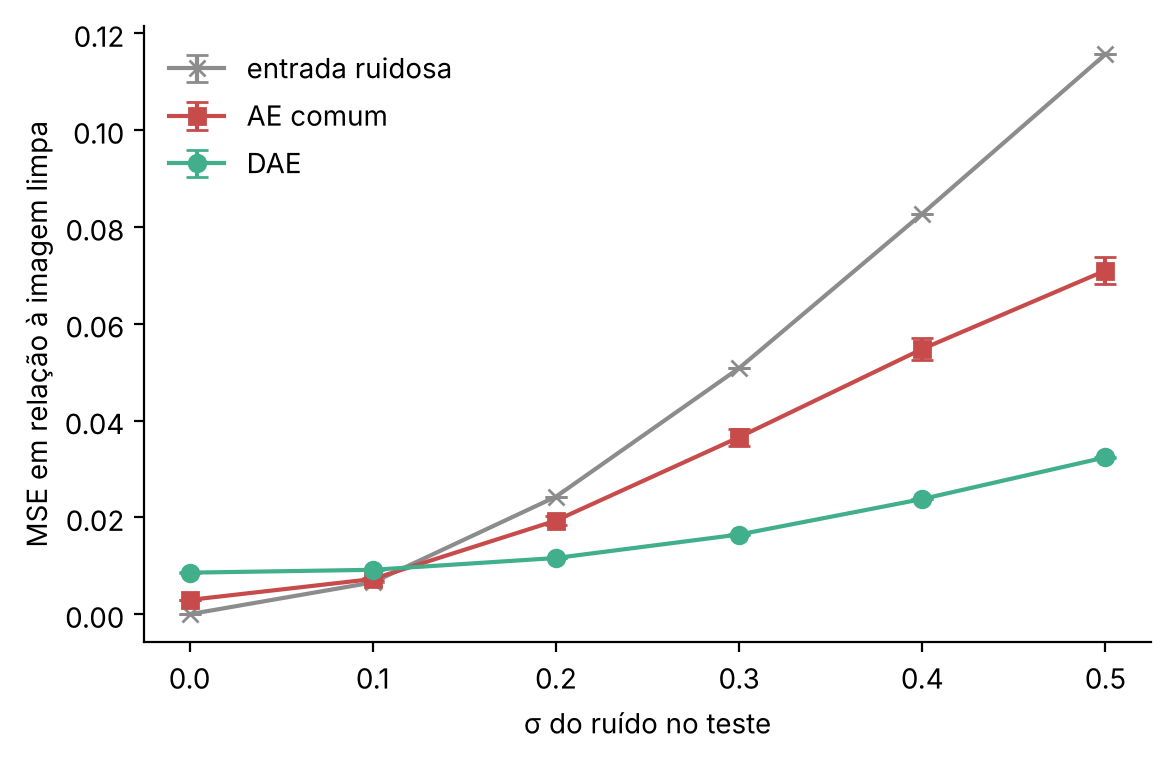

In [9]:
sigmas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
curvas = {"entrada ruidosa": [], "AE comum": [], "DAE": []}
for s in sigmas:
    torch.manual_seed(7)
    Xr = libs.ruido_gaussiano(X_te, s) if s > 0 else X_te
    curvas["entrada ruidosa"].append((torch.mean((Xr - X_te) ** 2).item(), 0.0))
    curvas["AE comum"].append(media_dp([libs.erro_reconstrucao(m, X_te, Xr) for m in aes]))
    curvas["DAE"].append(media_dp([libs.erro_reconstrucao(m, X_te, Xr) for m in daes]))

fig, ax = plt.subplots(figsize=(6.5, 4))
for (nome, v), cor, mk in zip(curvas.items(), [CORES["cinza"], CORES["pca"], CORES["verde"]], ["x", "s", "o"]):
    v = np.array(v)
    ax.errorbar(sigmas, v[:, 0], yerr=v[:, 1], marker=mk, capsize=4, color=cor, label=nome)
ax.set_xlabel("σ do ruído no teste"); ax.set_ylabel("MSE em relação à imagem limpa")
ax.legend(frameon=False); libs.limpar_eixos(ax)
libs.salvar(fig, "denoising_vs_sigma")
plt.show()

O DAE perde um pouco quando não há ruído, mas fica bem melhor quando o ruído aumenta.

O vetor $g(f(x)) - x$ mostra para onde o DAE "empurra" cada ponto. Num exemplo 2D com dados sobre um círculo, ele aponta de volta para os dados:

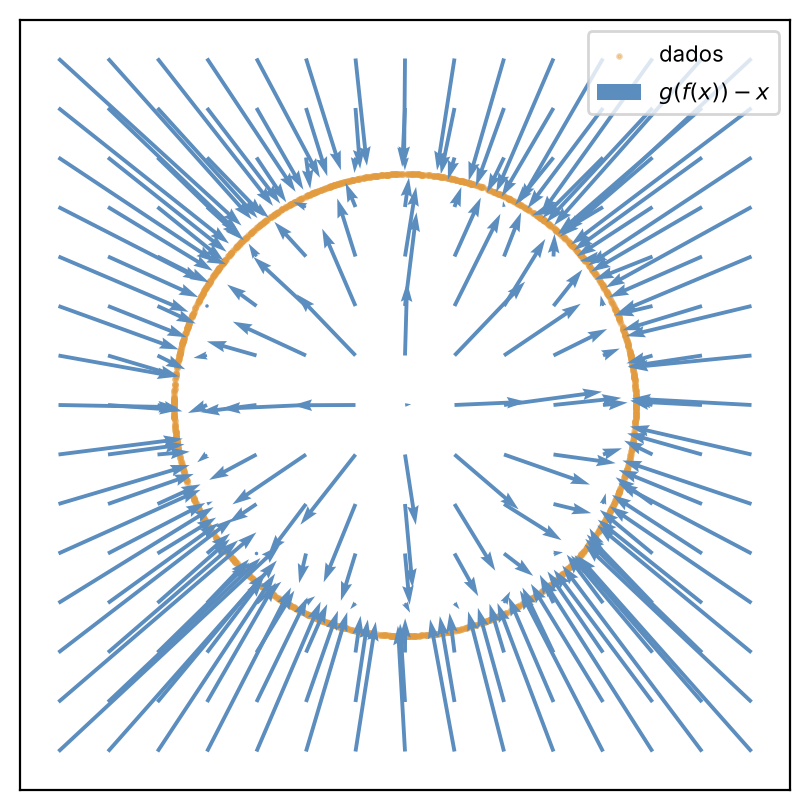

In [10]:
X_circ = libs.dados_circulo()
dae_2d = libs.treinar(libs.Autoencoder(n_entrada=2, n_codigo=64, ocultas=[64], saida="linear"),
                      X_circ, epocas=400, lr=3e-3, sigma_ruido=0.1)

g = torch.linspace(0.05, 0.95, 15)
gx, gy = torch.meshgrid(g, g, indexing="xy")
grade = torch.stack([gx.flatten(), gy.flatten()], dim=1)
campo = libs.reconstruir(dae_2d, grade) - grade

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_circ[:, 0], X_circ[:, 1], s=2, color=CORES["laranja"], alpha=0.4, label="dados")
ax.quiver(grade[:, 0], grade[:, 1], campo[:, 0], campo[:, 1], angles="xy", scale_units="xy", scale=1,
          width=0.005, color=CORES["azul"], label="$g(f(x)) - x$")
ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc="upper right", fontsize=8)
libs.salvar(fig, "dae_campo_vetorial")
plt.show()

## 6. Contractive autoencoder

Outra forma de regularizar: penalizar o quanto o código muda quando a entrada muda,

$$L\big(x,\, g(f(x))\big) + \lambda \left\lVert \frac{\partial f(x)}{\partial x} \right\rVert_F^2$$

O esperado é que o código continue sensível só a poucas direções (as que seguem os dados) e ignore o resto. Para ver isso, olhamos os valores singulares do jacobiano $\partial h / \partial x$ (encoder de uma camada com sigmoide, código de 64).

AE comum  MSE no teste: 0.0022 ± 0.0000
CAE       MSE no teste: 0.0109 ± 0.0002


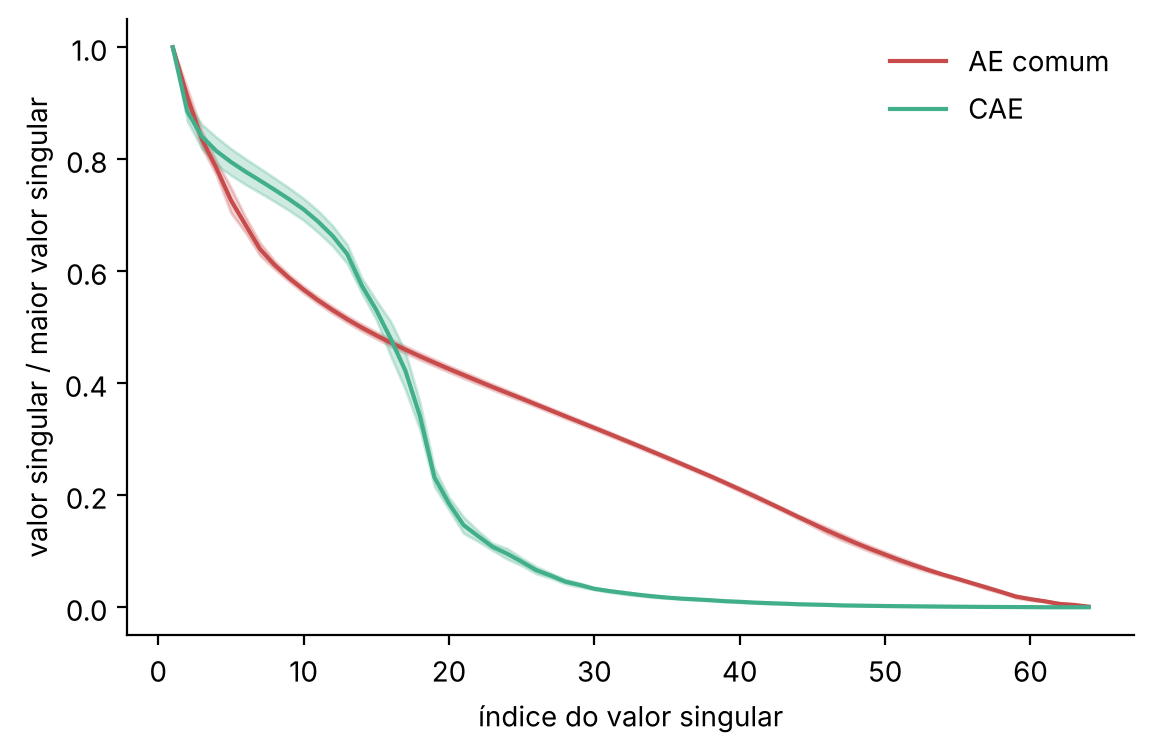

In [11]:
def avalia_jac(m):
    with torch.no_grad():
        s = torch.linalg.svdvals(libs.jacobiano_codigo(m, X_te)).mean(0)
    return np.concatenate([[libs.erro_reconstrucao(m, X_te)], (s / s[0]).numpy()])

criar = lambda: libs.Autoencoder(n_codigo=64, ativ_codigo="sigmoid")
_, r_ae = libs.varias_rodadas(criar, X_tr, N_RODADAS, avaliar=avalia_jac, epocas=300, lr=3e-3)
_, r_cae = libs.varias_rodadas(criar, X_tr, N_RODADAS, avaliar=avalia_jac, epocas=300, lr=3e-3, lambda_contr=3e-3)

fig, ax = plt.subplots(figsize=(6.5, 4))
for r, nome, cor in [(r_ae, "AE comum", CORES["pca"]), (r_cae, "CAE", CORES["verde"])]:
    m, d = media_dp(r)
    print(f"{nome:9s} MSE no teste: {m[0]:.4f} ± {d[0]:.4f}")
    i = np.arange(1, len(m))
    ax.plot(i, m[1:], color=cor, label=nome)
    ax.fill_between(i, m[1:] - d[1:], m[1:] + d[1:], color=cor, alpha=0.25)
ax.set_xlabel("índice do valor singular"); ax.set_ylabel("valor singular / maior valor singular")
ax.legend(frameon=False); libs.limpar_eixos(ax)
libs.salvar(fig, "cae_valores_singulares")
plt.show()

No AE comum os valores singulares caem devagar: o código reage a quase qualquer direção. No CAE eles caem rápido depois das primeiras direções, então o código só muda quando a entrada se move "ao longo" dos dados. O preço é um erro de reconstrução um pouco maior.